# 02 — Usure sur route : modèle de brosse + loi d'Archard

Sur route, un pneu agricole transmet un effort de traction $F_x$ (transport, remorque). Une partie de
l'empreinte **glisse** sur le revêtement : c'est là que la gomme s'use.

1. **Empreinte** : longueur $L = F_z/(b\,p_g)$, pression parabolique $p(x)$ avec $\int p\,b\,dx = F_z$.
2. **Brosse** (Pacejka, 2012) : poils de raideur $c_p$ ; en adhérence $u = s\,x$, glissement dès que
   $c_p u > \mu p(x)$ ; vitesse de glissement $v_g/V = s - du/dx$.
3. **Archard** (1953) : $dh = k_A\,p\,dS_g$ ⇒ volume usé par mètre parcouru
   $\dfrac{dV}{dX} = k_A\, b \displaystyle\int p(x)\,\frac{v_g}{V}\,dx$.

**Hypothèses** : petit glissement, $\mu = 0{,}8$ constant (pas de dépendance à la vitesse/température),
$C_s/F_z = 6$ (hypothèse, à identifier sur banc), $k_A$ **inconnu** → résultats en **indice relatif**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from agritire import plotting
plotting.setup()
pd.set_option("display.precision", 3)

from agritire.wear import (RoadContact, brush_state, pacejka_parabolic_force, archard_wear,
                           slip_for_force)
from agritire.terramechanics import Tire
tire = Tire(); Fz = 30e3
c = RoadContact(Fz, tire.width, tire.ground_pressure)
print(f"L = {c.length:.3f} m ; c_p = {c.bristle_stiffness:.3e} N/m³")

L = 0.330 m ; c_p = 5.096e+06 N/m³


## 1. Vérification : modèle de brosse numérique vs solution analytique de Pacejka

écart relatif max : 1.3999666097708667e-06


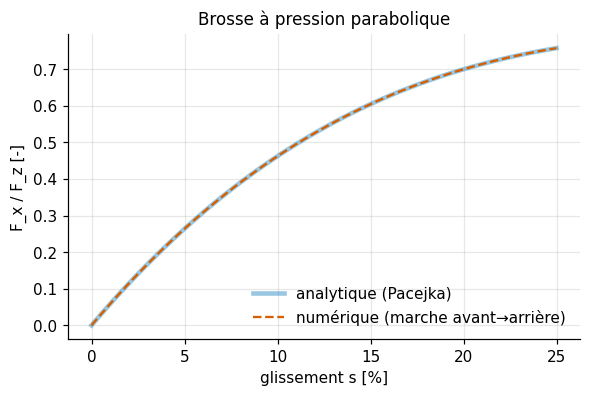

In [2]:
s = np.linspace(0, 0.25, 60)
num = [brush_state(c, si).force for si in s]
ana = [pacejka_parabolic_force(c, si) for si in s]
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(100 * s, np.array(ana) / Fz, lw=3, alpha=0.4, label="analytique (Pacejka)")
ax.plot(100 * s, np.array(num) / Fz, "--", label="numérique (marche avant→arrière)")
ax.set(xlabel="glissement s [%]", ylabel="F_x / F_z [-]", title="Brosse à pression parabolique")
ax.legend()
plotting.save(fig, "02_verification_brosse")
print("écart relatif max :", np.max(np.abs(np.array(num[1:]) - ana[1:]) / np.array(ana[1:])))

## 2. Zones d'adhérence et de glissement dans l'empreinte

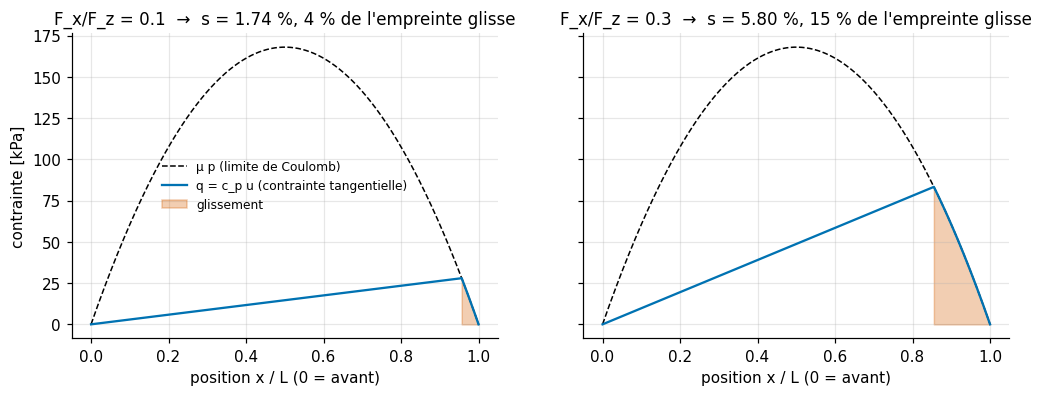

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, ratio in zip(axes, (0.1, 0.3)):
    w = archard_wear(c, ratio * Fz, keep_state=True)
    st = w.state
    ax.plot(st.x / c.length, c.mu * st.p / 1e3, "k--", lw=1, label="μ p (limite de Coulomb)")
    ax.plot(st.x / c.length, st.q / 1e3, label="q = c_p u (contrainte tangentielle)")
    ax.fill_between(st.x / c.length, 0, st.q / 1e3, where=st.sliding, alpha=0.3, color="C1", label="glissement")
    ax.set_title(f"F_x/F_z = {ratio}  →  s = {100*w.slip:.2f} %, {100*w.sliding_fraction:.0f} % de l'empreinte glisse")
    ax.set_xlabel("position x / L (0 = avant)")
axes[0].set_ylabel("contrainte [kPa]"); axes[0].legend(fontsize=8)
plotting.save(fig, "02_zones_glissement");

La zone de glissement apparaît à l'**arrière** de l'empreinte (là où la pression, donc la limite
d'adhérence, chute) et s'étend vers l'avant quand $F_x$ augmente.

**Bilan d'énergie** : en régime établi, la puissance de glissement $F_x\,s\,V$ est entièrement dissipée
par frottement dans la zone glissante, donc $E_f = F_x\,s$ [J/m]. C'est une vérification indépendante
de l'intégration (testée dans `tests/test_wear.py`).

In [4]:
for ratio in (0.05, 0.1, 0.2, 0.3):
    w = archard_wear(RoadContact(Fz, tire.width, tire.ground_pressure, n_points=100001), ratio * Fz)
    print(f"F_x/F_z = {ratio:4.2f} : E_f = {w.friction_energy:8.2f} J/m ; F_x·s = {ratio*Fz*w.slip:8.2f} J/m")

F_x/F_z = 0.05 : E_f =    12.77 J/m ; F_x·s =    12.77 J/m
F_x/F_z = 0.10 : E_f =    52.24 J/m ; F_x·s =    52.24 J/m
F_x/F_z = 0.20 : E_f =   219.43 J/m ; F_x·s =   219.46 J/m
F_x/F_z = 0.30 : E_f =   522.04 J/m ; F_x·s =   522.04 J/m


## 3. Sensibilité de l'usure à l'effort, à la pression et à la charge

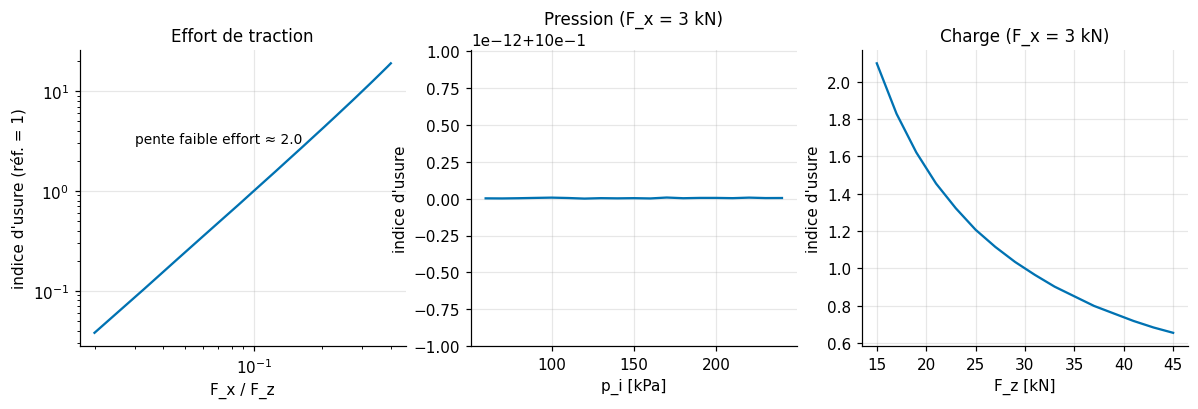

In [5]:
ref = archard_wear(c, 0.1 * Fz).archard_integral
ratios = np.linspace(0.02, 0.4, 30)
wear_fx = [archard_wear(c, r * Fz).archard_integral / ref for r in ratios]
pressures = np.linspace(60e3, 240e3, 19)
wear_p = [archard_wear(RoadContact(Fz, tire.width, p + tire.carcass_pressure), 0.1 * Fz).archard_integral / ref
          for p in pressures]
loads = np.linspace(15e3, 45e3, 16)
# à effort de traction constant (3 kN) : la charge seule varie
wear_w = [archard_wear(RoadContact(Wi, tire.width, tire.ground_pressure), 0.1 * Fz).archard_integral / ref
          for Wi in loads]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].loglog(ratios, wear_fx); axes[0].set(xlabel="F_x / F_z", ylabel="indice d'usure (réf. = 1)", title="Effort de traction")
slope = np.polyfit(np.log(ratios[:10]), np.log(wear_fx[:10]), 1)[0]
axes[0].text(0.03, 3, f"pente faible effort ≈ {slope:.1f}", fontsize=9)
axes[1].plot(pressures / 1e3, wear_p); axes[1].set(xlabel="p_i [kPa]", title="Pression (F_x = 3 kN)")
axes[2].plot(loads / 1e3, wear_w); axes[2].set(xlabel="F_z [kN]", title="Charge (F_x = 3 kN)")
for ax in axes[1:]: ax.set_ylabel("indice d'usure")
plotting.save(fig, "02_sensibilites_usure");

Lecture :
- l'usure croît **très fortement** avec l'effort transmis (pente ≈ 3 en log-log aux faibles efforts :
  $s \propto F_x$ et la zone glissante s'étend), d'où l'intérêt de limiter le patinage sur route
  (lestage, répartition des efforts, pression adaptée) ;
- à effort donné, l'effet de la **pression est nul par construction** dans ce modèle : avec une
  pression parabolique et $C_s/F_z$ fixé, la solution de la brosse ne dépend que de $\theta s$ avec
  $\theta = C_s/(3\mu F_z)$ ; raccourcir l'empreinte raidit les poils d'autant (courbe plate). C'est une
  **limite à afficher**, pas un résultat : en réalité $C_s$ dépend de la pression et de la charge, et
  doit être mesurée sur banc pour que le modèle soit prédictif ;
- à effort constant, **augmenter la charge** réduit le glissement nécessaire, donc l'usure ;
- l'indice est **relatif** : sans essai d'usure de référence pour identifier $k_A$, un volume absolu
  (mm³/km) n'aurait aucune valeur prédictive.

**Ce que le modèle ne capture pas** : les crampons (flexion et frottement des pavés en entrée/sortie
d'empreinte, principal mécanisme d'usure des pneus agricoles sur route), les différences de rayon de
roulement dans la largeur, la température, l'abrasivité du revêtement.